In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import backend as K
from keras.utils import plot_model

from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

from sklearn.manifold import TSNE

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB



(10000, 2)


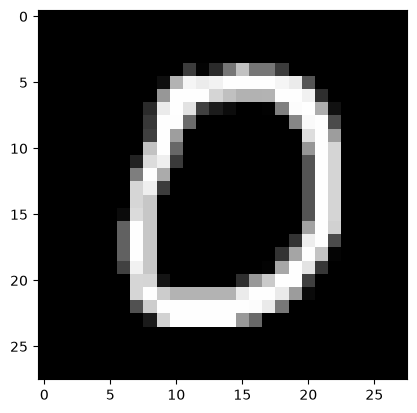

In [12]:
dfF = pd.read_csv(r'C:\Users\User\Documents\Content Data Science\mnist_test.csv', header=None)
#df['pixels'] = df.index.map(lambda x: np.array(df.iloc[x][1:]))

df = pd.DataFrame({'label': dfF.iloc[:, 0], 
                   'pixels': list(dfF.iloc[:, 1:].to_numpy())})

#dropcols = df.columns[(df.columns !=0)* (df. columns != 'pixels')]
#df.drop(dropcols, axis=1, inplace=True)
#df.columns = ['label', 'pixels']

print(df.shape)

df.head()

fig = plt.imshow(df['pixels'][10].reshape(28, 28), cmap='gray')

In [38]:
labels = [1, 6, 8]
colors = ['red', 'blue', 'green']

x = np.array([df['pixels'][i] for i in df.index 
             if df['label'][i] in labels])
y = np.array([df['label'][i] for i in df.index 
             if df['label'][i] in labels])

print('X shape: ' + str(x.shape))
print('Y shape: ' + str(y.shape))

X shape: (3067, 784)
Y shape: (3067,)


XPCA shape: (3067, 3)


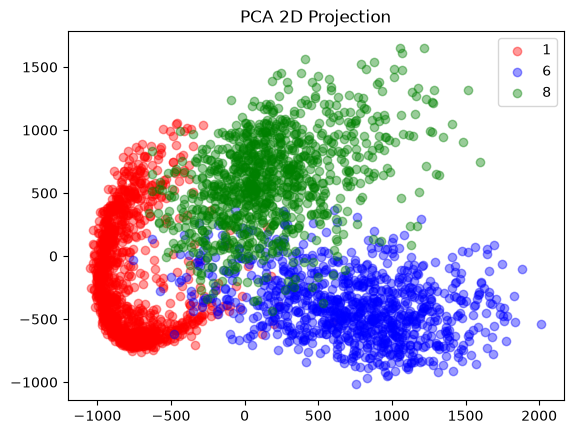

In [22]:
#Principal Component Analysis
pca = PCA(3)
XPCA = pca.fit_transform(x)
print(f'XPCA shape: {XPCA.shape}') 

componentX = 1
componentY = 2

fig, ax = plt.subplots()
for i in range(len(labels)):
    ax.scatter(XPCA[y == labels[i], componentX - 1],
              XPCA[ y == labels[i], componentY - 1],
              c=colors[i], label=labels[i], alpha=0.4)
l = ax.legend()
plt.title('PCA 2D Projection')
plt.show()

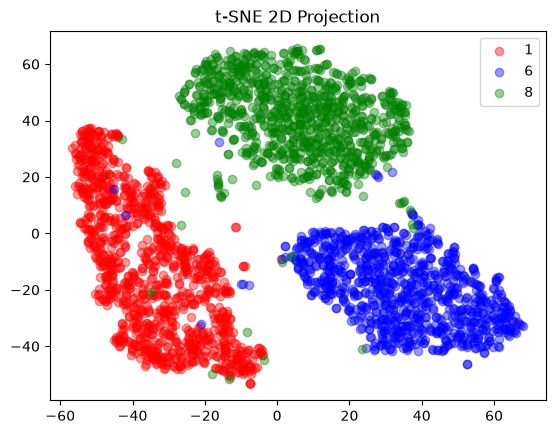

In [28]:
perplexity = 30
learning_rate = 200
n_iter = 1000

tsne = TSNE(2, perplexity = perplexity, learning_rate = learning_rate, max_iter=n_iter, random_state = 42)
XTSNE = tsne.fit_transform(x)

fig, ax = plt.subplots()
for i in range(len(labels)):
    ax.scatter(XTSNE[y == labels[i], 0],
              XTSNE[ y == labels[i], 1],
              c=colors[i], label=labels[i], alpha=0.4)
l =ax.legend()
plt.title('t-SNE 2D Projection')
plt.show()


In [40]:
def fitMyModel(model,features, test_size):
    if features == 'raw':
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = test_size, random_state = 42)
    elif features == 'tsne':
        x_train, x_test, y_train, y_test = train_test_split(XTSNE, y, test_size = test_size, random_state=42)
    else:
        pca_feat = PCA(features)
        x_pca_feat = pca_feat.fit_transform(x)
        x_train, x_test, y_train, y_test, = train_test_split(x_pca_feat, y, test_size=test_size, random_state=42)
    print('Training Samples: ' + str(x_train.shape[0]))
    print('Testing Samples: '+ str(x_test.shape[0]))
    print('Number of features: ' + str(x_train.shape[1]))

    if model == 'nb':
        clf = GaussianNB()
    elif model == 'svm':
        clf = SVC(gamma='auto')
    elif model == 'rf':
        clf = RandomForestClassifier(200, criterion = 'gini', max_depth=None, max_features = np.min([10, x_train.shape[1]]))

    clf.fit(x_train, y_train)

    learningScore = clf.score(x_train, y_train)
    generalizationScore = clf.score(x_test, y_test)
    print('Learning score: ' + str(learningScore))
    print('Generalization score: ' + str(generalizationScore))

    return generalizationScore

model = 'rf'
features = 'raw'
test_size = 0.2

score = fitMyModel(model, features, test_size)


Training Samples: 2453
Testing Samples: 614
Number of features: 784
Learning score: 1.0
Generalization score: 0.990228013029316



raw - svm
Training Samples: 2453
Testing Samples: 614
Number of features: 784
Learning score: 1.0
Generalization score: 0.34201954397394135

raw - nb
Training Samples: 2453
Testing Samples: 614
Number of features: 784
Learning score: 0.9196901752955564
Generalization score: 0.8941368078175895

raw - rf
Training Samples: 2453
Testing Samples: 614
Number of features: 784
Learning score: 1.0
Generalization score: 0.99185667752443

pca - svm
Training Samples: 2453
Testing Samples: 614
Number of features: 10
Learning score: 1.0
Generalization score: 0.34201954397394135

pca - nb
Training Samples: 2453
Testing Samples: 614
Number of features: 10
Learning score: 0.9543416225030574
Generalization score: 0.9560260586319218

pca - rf
Training Samples: 2453
Testing Samples: 614
Number of features: 10
Learning score: 1.0
Generalization score: 0.9674267100977199

tsne - svm
Training Samples: 2453
Testing Samples: 614
Number of features: 2
Learning score: 0.9979616795760293
Generalization score: 0.

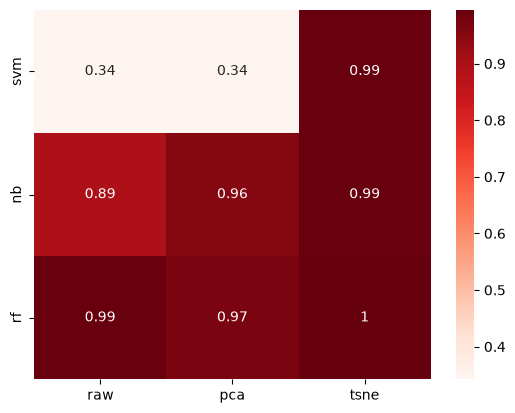

In [45]:
comparison_table = pd.DataFrame(columns = ['raw', 'pca', 'tsne'], index = ['svm', 'nb', 'rf'])
for f in comparison_table.columns:
    for m in comparison_table.index:
        print('\n' + f + ' - ' + m)
        comparison_table.loc[m,f] = fitMyModel(m, f if f!='pca' else 10, 0.2)
fig = sns.heatmap(comparison_table.astype('float'), annot=True, cmap='Reds')


(60000, 784)
(10000, 784)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_24 (InputLayer)     │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 15)             │         3,015 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,015 (625.06 KB)

 Trainable params: 160,015 (625.06 KB)

 Non-trainable params: 0 (0.00 B)

... (7 outputs left out)

 Total params: 320,799 (1.22 MB)

 Trainable params: 320,799 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.1874 - val_loss: 0.1345
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.1300 - val_loss: 0.1234
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1205 - val_loss: 0.1159
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.1152 - val_loss: 0.1123
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1122 - val_loss: 0.1099
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.1101 - val_loss: 0.1081
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.1085 - val_loss: 0.1067
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.1072 - val_loss: 0.1055
Epoch 9/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.1061 - val_loss: 0.1045
Epoch 10/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.1052 - val_loss: 0.1037
Epoch 11/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.1044 - val_loss: 0.1030
Epoch 12/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 

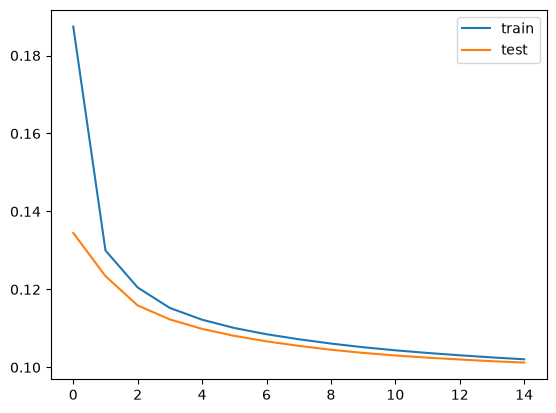

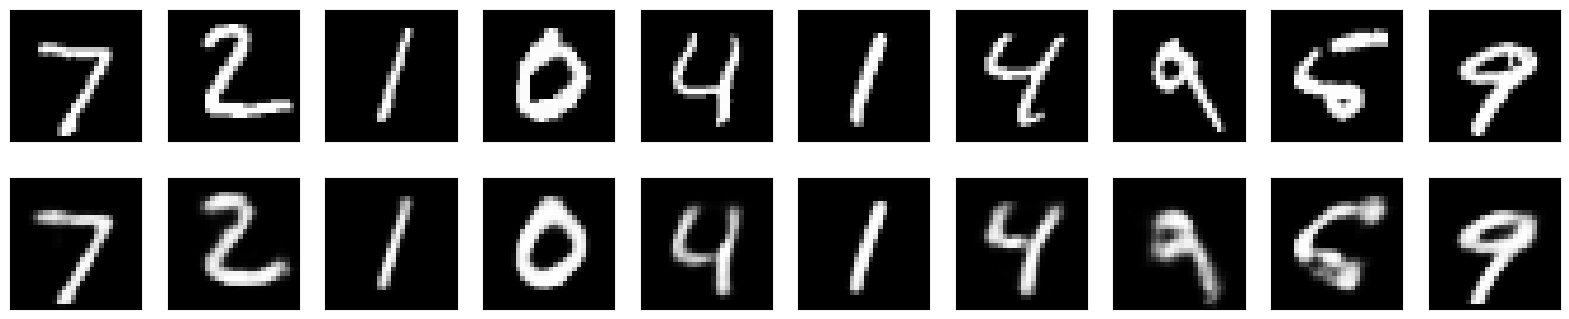

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [60]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = np.array([x.flatten() for x in x_train]).astype('float32')/255.
x_test = np.array([x.flatten() for x in x_test]).astype('float32')/255.

print(x_train.shape)
print(x_test.shape)

latent_space_dim = 15

encoder_inputs = keras.Input(shape=(784,))
hidden1 = layers.Dense(200, activation='relu')(encoder_inputs)
latent_space = layers.Dense(latent_space_dim, activation='relu')(hidden1)

encoder = keras.Model(encoder_inputs, latent_space, name='encoder')

#plot_model(encoder, to_file='encodersimple.png', show_shapes=True)
encoder.summary()

decoder_inputs = keras.Input(shape=(latent_space_dim,))
hidden2 = layers.Dense(200, activation='relu')(decoder_inputs)
decoder_outputs = layers.Dense(784, activation='sigmoid')(hidden2)

decoder = keras.Model(decoder_inputs, decoder_outputs, name='decoder')

#plot_model(decoder, to_file='decodersimple.png', show_shapes = True)
decoder.summary()

outputs = decoder(encoder(encoder_inputs))
autoencoder = keras.Model(encoder_inputs, outputs, name='autoencoder')
autoencoder.summary()

#reconstruction_loss = keras.losses.binary_crossentropy(encoder_inputs, outputs)* 784
#autoencoder_loss = tf.reduce_mean(reconstruction_loss)

#autoencoder.add_loss(autoencoder_loss)
#autoencoder.compile(optimizer='adam')

autoencoder.compile(optimizer='adam', loss= 'binary_crossentropy')

history = autoencoder.fit(x_train, x_train, epochs=15, batch_size=128, 
                          validation_data = (x_test, x_test))

autoencoder.save_weights('./autoencoder-77.5.weights.h5')

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()

n=10
plt.figure(figsize=(20, 4))
for i in range(n):
    ax = plt.subplot(2, n, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    ax = plt.subplot(2, n, i + 1 + n)
    encoded_img = encoder.predict(np.array([x_test[i]]).reshape(1, 784))
    decoded_img = decoder.predict(encoded_img).reshape(28, 28)
    plt.imshow(decoded_img, cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.show()

x_test_latent = encoder.predict(x_test)
